# 收益情景测算

基于用户分层结果，测算发券活动的成本、增量净收益和盈亏平衡条件，再比较两种选人策略。


## 1. 读取用户分层结果

本文件读取全量 1,000 名用户的分层结果，选取其中 89 名潜力用户，测算不同发券假设下的成本和收益。


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# 读取全量用户分层结果
project_dir = Path.cwd()
if project_dir.name == 'code':
    project_dir = project_dir.parent
data_path = project_dir / 'outputs' / 'improved' / 'user_segments.csv'
if not data_path.exists():
    raise FileNotFoundError('请先从头运行 用户分层分析.ipynb，生成全量用户分层表。')
users = pd.read_csv(data_path)

scenario_dir = project_dir / 'outputs' / 'scenarios'
scenario_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 筛选核心与潜力人群
core_labels = ['核心VIP', '重要价值用户']
potential_labels = ['纠结土豪', '高潜沉睡用户', '犹豫型潜力用户', '高潜流失客']
core_users = users.loc[users['User_Segment'].isin(core_labels)].copy()
potential_users = users.loc[users['User_Segment'].isin(potential_labels)].copy()

print('全部用户', len(users))
print('核心用户', len(core_users))
print('潜力用户', len(potential_users))

全部用户 1000
核心用户 70
潜力用户 89


## 2. 测算参数

目标人数为 89 人，客单价取样本均值 104.039。购买率、毛利率、券额、联系成本和预算按下表设定。

每位购买用户按一笔订单、一次核销计算，客单价和商品毛利率均采用优惠前口径。


In [2]:
# 目标人数
target_count = len(potential_users)

# 客单价取样本均值
assumed_aov = float(users['Average_Order_Value'].mean())

# 购买率与成本参数
natural_rate = 0.01
gross_margin = 0.40
coupon_value = 10.0
contact_cost = 0.5
total_budget = 10000.0

# 三档发券后购买率
scenario_rates = pd.DataFrame({
    '情景': ['较低提升', '中等提升', '较高提升'],
    '活动后购买率': [0.02, 0.05, 0.20],
})

# 参数及来源
assumptions = pd.DataFrame({
    '项目': ['目标人数', '假设客单价', '自然购买率', '毛利率', '每次核销优惠额', '每人联系成本', '预算上限'],
    '当前取值': [target_count, assumed_aov, natural_rate, gross_margin, coupon_value, contact_cost, total_budget],
    '依据': [
        '由用户分层筛选',
        '样本平均订单金额，用于未来活动为假设',
        '练习假设', '练习假设', '练习假设', '练习假设', '练习假设',
    ],
})
display(assumptions)
display(scenario_rates)

,项目,当前取值,依据
0,目标人数,89.000,由用户分层筛选
1,假设客单价,104.039,样本平均订单金额，用于未来活动为假设
2,自然购买率,0.010,练习假设
3,毛利率,0.400,练习假设
4,每次核销优惠额,10.000,练习假设
5,每人联系成本,0.500,练习假设
6,预算上限,10000.000,练习假设


,情景,活动后购买率
0,较低提升,0.02
1,中等提升,0.05
2,较高提升,0.20


## 3. 计算增量收益

按新增购买带来的毛利，扣除优惠和联系成本，计算增量净收益。

```text
新增购买人数 = 人数 ×（发券后购买率 − 自然购买率）
增量销售额 = 新增购买人数 × 客单价
增量毛利 = 增量销售额 × 毛利率
优惠成本 = 人数 × 发券后购买率 × 每次核销优惠额
联系成本 = 人数 × 每人联系成本
增量净收益 = 增量毛利 − 优惠成本 − 联系成本
ROI = 增量净收益 /（优惠成本 + 联系成本）
```


In [3]:
# n 为目标人数，p0 为自然购买率，p1 为发券后购买率
def estimate_scenario(n, p0, p1, aov, margin, coupon, contact):
    # 参数范围检查
    if not (0 <= p0 <= 1 and 0 <= p1 <= 1 and 0 <= margin <= 1):
        raise ValueError('购买率和毛利率应在 0～1 之间。')
    if n < 0 or n != int(n) or min(aov, coupon, contact) < 0:
        raise ValueError('人数应为非负整数，金额参数应为非负数。')

    # 预计新增购买人数
    extra_buyers = n * (p1 - p0)

    # 增量销售额与毛利
    extra_sales = extra_buyers * aov
    extra_gross_profit = extra_sales * margin

    # 券成本覆盖活动组所有购买用户
    expected_coupon_cost = n * p1 * coupon

    # 联系成本按目标人数计算
    expected_contact_cost = n * contact

    # 营销成本与净收益
    marketing_cost = expected_coupon_cost + expected_contact_cost
    extra_net_profit = extra_gross_profit - marketing_cost

    # 计算 ROI
    roi = extra_net_profit / marketing_cost if marketing_cost > 0 else None

    # 返回参数和测算结果
    return {
        '目标人数': int(n),
        '自然购买率': p0,
        '活动后购买率': p1,
        '绝对提升(百分点)': (p1 - p0) * 100,
        '假设客单价': aov,
        '假设毛利率': margin,
        '每次核销优惠额': coupon,
        '每人联系成本': contact,
        '预计新增购买人数': extra_buyers,
        '预计增量销售额': extra_sales,
        '预计增量毛利': extra_gross_profit,
        '预计优惠成本': expected_coupon_cost,
        '预计联系成本': expected_contact_cost,
        '预计营销成本': marketing_cost,
        '预计增量净收益': extra_net_profit,
        'ROI': roi,
    }

## 4. 三档购买率情景

固定人数和成本参数，将发券后购买率分别设为 2%、5%、20%。测算得到的增量净收益分别为 −25.26、59.15、481.22。


In [4]:
# 计算三档购买率情景
scenario_rows = []

for _, row in scenario_rates.iterrows():
    result = estimate_scenario(
        n=target_count,
        p0=natural_rate,
        p1=float(row['活动后购买率']),
        aov=assumed_aov,
        margin=gross_margin,
        coupon=coupon_value,
        contact=contact_cost,
    )
    # 情景名称与预算核对
    result['情景'] = row['情景']
    result['预算上限'] = total_budget
    result['预算内'] = result['预计营销成本'] <= total_budget
    scenario_rows.append(result)

# 汇总结果
scenario_results = pd.DataFrame(scenario_rows)
scenario_view = scenario_results[[
    '情景', '目标人数', '自然购买率', '活动后购买率',
    '预计增量销售额', '预计增量毛利', '预计优惠成本',
    '预计联系成本', '预计增量净收益', '预算内',
]].copy()

# 展示值四舍五入
display(scenario_view.round(2))



,情景,目标人数,自然购买率,活动后购买率,预计增量销售额,预计增量毛利,预计优惠成本,预计联系成本,预计增量净收益,预算内
0,较低提升,89,0.01,0.02,92.59,37.04,17.8,44.5,-25.26,True
1,中等提升,89,0.01,0.05,370.38,148.15,44.5,44.5,59.15,True
2,较高提升,89,0.01,0.20,1759.30,703.72,178.0,44.5,481.22,True


## 5. 收益对比与盈亏平衡

绘制三档净收益对比图，并求增量净收益为 0 时的发券后购买率。当前参数下，盈亏平衡购买率约为 2.90%。

```text
盈亏平衡购买率 =（自然购买率 × 客单价 × 毛利率 + 每人联系成本）
                 /（客单价 × 毛利率 − 券额）
```


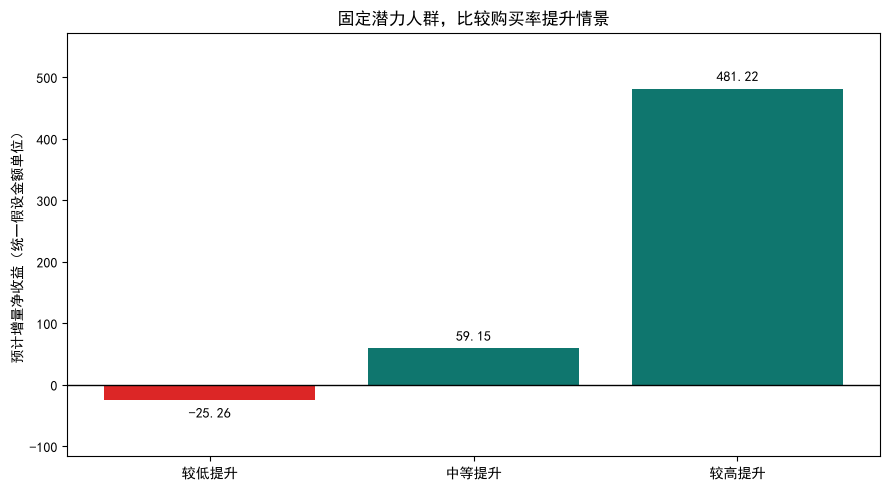

其他条件固定时，活动后购买率约达到 2.90% 时盈亏平衡。
相对自然购买率，需要增加约 1.90 个百分点。


In [5]:
# 按净收益正负设置颜色
bar_colors = [
    '#DC2626' if value < 0 else '#0F766E'
    for value in scenario_results['预计增量净收益']
]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    scenario_results['情景'],
    scenario_results['预计增量净收益'],
    color=bar_colors,
)
ax.axhline(0, color='black', linewidth=1)
ax.set_title('固定潜力人群，比较购买率提升情景')
ax.set_ylabel('预计增量净收益（统一假设金额单位）')

ax.bar_label(bars, fmt='%.2f', padding=4)
ax.margins(y=0.18)
fig.tight_layout()
fig.savefig(scenario_dir / 'scenario_net_profit.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# 计算盈亏平衡购买率
gross_profit_per_order = assumed_aov * gross_margin
if gross_profit_per_order > coupon_value:
    break_even_rate = (
        natural_rate * gross_profit_per_order + contact_cost
    ) / (gross_profit_per_order - coupon_value)
    if break_even_rate <= 1:
        print(f'其他条件固定时，活动后购买率约达到 {break_even_rate:.2%} 时盈亏平衡。')
        print(f'相对自然购买率，需要增加约 {(break_even_rate - natural_rate) * 100:.2f} 个百分点。')
    else:
        print('当前条件下，公式所需购买率超过 100%，需要调整券额或其他条件。')
else:
    break_even_rate = None
    print('当前每单毛利不高于核销优惠额，在这些参数下无法获得正的增量净收益。')

## 6. 券额与毛利率比较

固定发券后购买率为 5%，组合比较券额 5、10、15 和毛利率 20%、40%、60%，观察净收益的变化。


In [6]:
# 固定发券后购买率
fixed_activity_rate = 0.05
sensitivity_rows = []

# 毛利率与券额的九种组合
for margin in [0.20, 0.40, 0.60]:
    for coupon in [5.0, 10.0, 15.0]:
        result = estimate_scenario(
            n=target_count, p0=natural_rate, p1=fixed_activity_rate,
            aov=assumed_aov, margin=margin, coupon=coupon, contact=contact_cost,
        )
        sensitivity_rows.append(result)

# 按毛利率和券额展示净收益
sensitivity_results = pd.DataFrame(sensitivity_rows)
sensitivity_table = sensitivity_results.pivot(
    index='假设毛利率', columns='每次核销优惠额', values='预计增量净收益'
)
display(sensitivity_table.round(2))

每次核销优惠额,5.0,10.0,15.0
假设毛利率,,,
0.2,7.33,-14.92,-37.17
0.4,81.40,59.15,36.90
0.6,155.48,133.23,110.98


## 7. 两种选人策略比较

方案 A 按 RFM 基础分的 80% 分位数筛选，覆盖 200 人；方案 B 选择核心与潜力用户，覆盖 159 人。

两种方案按核心、潜力、其他三类使用相同的购买率设定，分别计算成本和净收益。


In [7]:
# 按核心、潜力、其他划分用户
response_users = users.copy()
response_users['响应类型'] = '其他'
response_users.loc[response_users['User_Segment'].isin(core_labels), '响应类型'] = '核心'
response_users.loc[response_users['User_Segment'].isin(potential_labels), '响应类型'] = '潜力'

# 两种策略共用的购买率参数
response_parameters = pd.DataFrame({
    '响应类型': ['核心', '潜力', '其他'],
    '自然购买率': [0.25, 0.01, 0.20],
    '活动后购买率': [0.30, 0.20, 0.30],
})
display(response_parameters)

# 按用户类型匹配购买率
response_users = response_users.merge(
    response_parameters, on='响应类型', how='left', validate='many_to_one'
)

# 筛选两种策略的目标用户
threshold = response_users['RFM_Score'].quantile(0.80)
strategy_a = response_users.loc[response_users['RFM_Score'] >= threshold].copy()
strategy_b = response_users.loc[response_users['响应类型'].isin(['核心', '潜力'])].copy()

# 按策略和用户类型测算收益
strategy_rows = []
for strategy_name, audience in {'方案A_基础分前20%': strategy_a, '方案B_核心与潜力': strategy_b}.items():
    for response_type, group in audience.groupby('响应类型'):
        parameters = group.iloc[0]
        result = estimate_scenario(
            n=len(group),
            p0=float(parameters['自然购买率']),
            p1=float(parameters['活动后购买率']),
            aov=assumed_aov,
            margin=gross_margin,
            coupon=coupon_value,
            contact=contact_cost,
        )
        result['策略'] = strategy_name
        result['响应类型'] = response_type
        strategy_rows.append(result)

# 汇总各类用户的结果并计算整体 ROI
strategy_details = pd.DataFrame(strategy_rows)
sum_columns = [
    '目标人数', '预计增量销售额', '预计增量毛利',
    '预计优惠成本', '预计联系成本', '预计营销成本', '预计增量净收益',
]
strategy_comparison = strategy_details.groupby('策略')[sum_columns].sum()
strategy_comparison['ROI'] = (
    strategy_comparison['预计增量净收益']
    / strategy_comparison['预计营销成本'].where(strategy_comparison['预计营销成本'] > 0)
)
strategy_comparison['预算上限'] = total_budget
strategy_comparison['预算内'] = strategy_comparison['预计营销成本'] <= total_budget
display(strategy_details.round(2))
display(strategy_comparison.round(2))

,响应类型,自然购买率,活动后购买率
0,核心,0.25,0.3
1,潜力,0.01,0.2
2,其他,0.20,0.3


,目标人数,自然购买率,活动后购买率,绝对提升(百分点),假设客单价,假设毛利率,每次核销优惠额,每人联系成本,预计新增购买人数,预计增量销售额,预计增量毛利,预计优惠成本,预计联系成本,预计营销成本,预计增量净收益,ROI,策略,响应类型
0,109,0.20,0.3,10.0,104.04,0.4,10.0,0.5,10.90,1134.03,453.61,327.0,54.5,381.5,72.11,0.19,方案A_基础分前20%,其他
1,68,0.25,0.3,5.0,104.04,0.4,10.0,0.5,3.40,353.73,141.49,204.0,34.0,238.0,-96.51,-0.41,方案A_基础分前20%,核心
2,23,0.01,0.2,19.0,104.04,0.4,10.0,0.5,4.37,454.65,181.86,46.0,11.5,57.5,124.36,2.16,方案A_基础分前20%,潜力
3,70,0.25,0.3,5.0,104.04,0.4,10.0,0.5,3.50,364.14,145.65,210.0,35.0,245.0,-99.35,-0.41,方案B_核心与潜力,核心
4,89,0.01,0.2,19.0,104.04,0.4,10.0,0.5,16.91,1759.30,703.72,178.0,44.5,222.5,481.22,2.16,方案B_核心与潜力,潜力


,目标人数,预计增量销售额,预计增量毛利,预计优惠成本,预计联系成本,预计营销成本,预计增量净收益,ROI,预算上限,预算内
策略,,,,,,,,,,
方案A_基础分前20%,200,1942.41,776.96,577.0,100.0,677.0,99.96,0.15,10000.0,True
方案B_核心与潜力,159,2123.44,849.37,388.0,79.5,467.5,381.87,0.82,10000.0,True


## 8. 保存测算结果

将参数表、收益情景、成本比较和策略结果保存到 `outputs/scenarios`。


In [8]:
# 保存参数和结果
assumptions.to_csv(scenario_dir / 'assumptions.csv', index=False, encoding='utf-8-sig')
scenario_results.to_csv(scenario_dir / 'scenario_results.csv', index=False, encoding='utf-8-sig')
sensitivity_results.to_csv(scenario_dir / 'cost_margin_sensitivity.csv', index=False, encoding='utf-8-sig')
sensitivity_table.to_csv(scenario_dir / 'cost_margin_matrix.csv', encoding='utf-8-sig')
response_parameters.to_csv(scenario_dir / 'response_parameters.csv', index=False, encoding='utf-8-sig')
strategy_details.to_csv(scenario_dir / 'strategy_details.csv', index=False, encoding='utf-8-sig')
strategy_comparison.to_csv(scenario_dir / 'strategy_comparison.csv', encoding='utf-8-sig')
print('结果保存位置', scenario_dir)

结果保存位置 C:\Users\86156\Documents\ChatGPT\sql\电商用户分层项目_跟做包\outputs\scenarios
